In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import numpy as np


In [25]:
# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_filtered_15_min.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Ensure the data is sorted by timestamp (just in case)
df.sort_index(inplace=True)


In [26]:
# Define ARIMA model parameters (p, d, q)
p = 3  # Autoregressive (AR) order
d = 1  # Integrated (I) order (degree of differencing)
q = 2  # Moving Average (MA) order

# Create ARIMA model  
model = ARIMA(df['Parkings'], order=(p, d, q))

# Fit ARIMA model to the data
arima_results = model.fit()


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 15min will be used.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 15min will be used.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 15min will be used.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


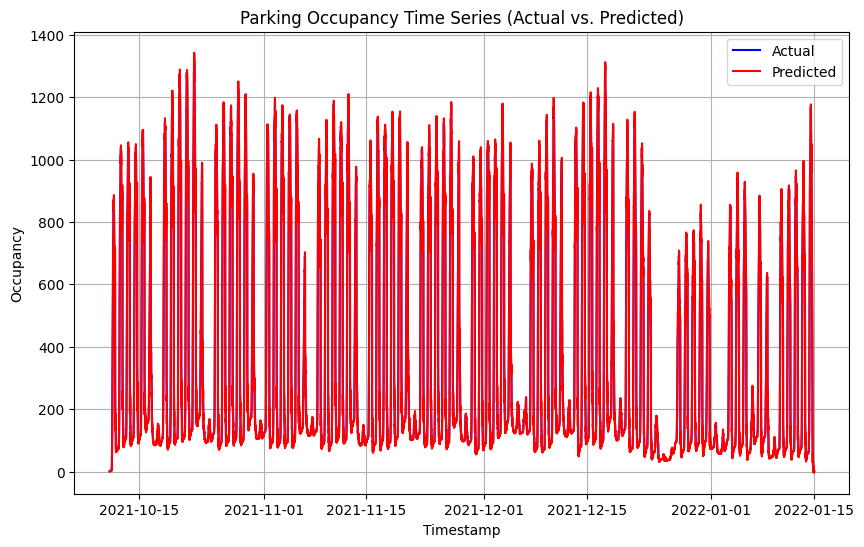

In [27]:
# Generate predictions
predictions = arima_results.predict(start=df.index[0], end=df.index[-1])

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Parkings'], color='blue', label='Actual')
plt.plot(predictions.index, predictions, color='red', label='Predicted')
plt.title('Parking Occupancy Time Series (Actual vs. Predicted)')
plt.xlabel('Timestamp')
plt.ylabel('Occupancy')
plt.legend()
plt.grid(True)
plt.show()


Mean Absolute Error (MAE): 15.7153030814536
Mean Squared Error (MSE): 1554.6511105997934
Root Mean Squared Error (RMSE): 39.42906428765199


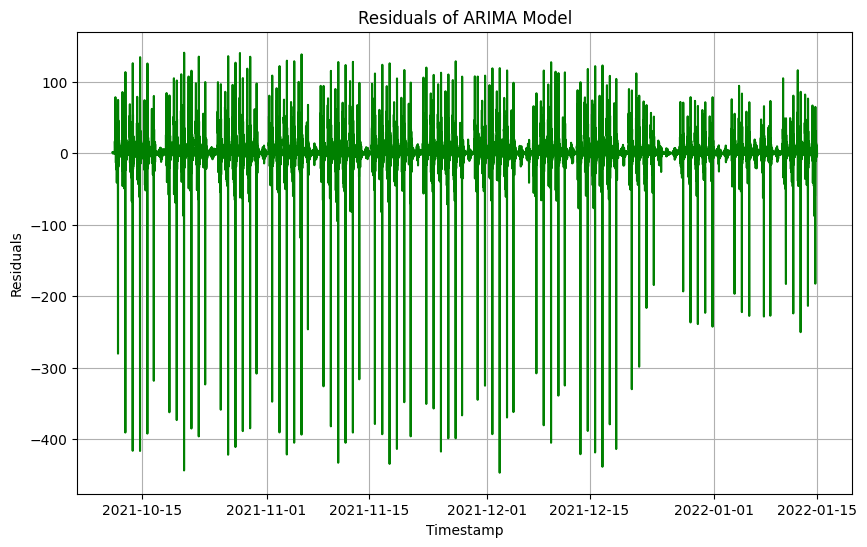

In [28]:
# Evaluate model performance
mae = mean_absolute_error(df['Parkings'], predictions)
mse = mean_squared_error(df['Parkings'], predictions)
rmse = np.sqrt(mse)

print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

# Plot residuals
residuals = df['Parkings'] - predictions
plt.figure(figsize=(10, 6))
plt.plot(df.index, residuals, color='green')
plt.title('Residuals of ARIMA Model')
plt.xlabel('Timestamp')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()
